# Итоговый проект: классификация обращений пользователей

**Курс:** aiml-5 «Машинное обучение и нейросети»
**Задача:** по тексту обращения в службу технической поддержки определить его категорию (8 классов).

**Датасет:** [IT Service Ticket Classification Dataset](https://www.kaggle.com/datasets/adisongoh/it-service-ticket-classification-dataset)
(`all_tickets_processed_improved_v3.csv`, 47 837 обращений, колонки `Document` и `Topic_group`).

**Что сделано в ноутбуке:**
1. Загрузка данных и разведочный анализ (EDA).
2. Предобработка текста: очистка, нормализация, стоп-слова, лемматизация.
3. Разбиение train/test 80/20 со `stratify`.
4. TF-IDF + классификаторы в `sklearn.pipeline.Pipeline` (LogisticRegression, LinearSVC, ComplementNB).
5. Нейросеть MLP на PyTorch.
6. Логирование всех запусков в MLflow (единый эксперимент `ticket-classification`).
7. Метрики, матрицы ошибок, сводная таблица, анализ ошибок и выводы.

**Воспроизводимость:** ноутбук выполняется от начала до конца (`Kernel → Restart and Run All`) без ошибок;
датасет лежит в `data/all_tickets_processed_improved_v3.csv`, зависимости — в `requirements.txt`, `README.md` — рядом.

## Шаг 0. Окружение и импорт библиотек

Если библиотеки ещё не установлены, раскомментируйте ячейку ниже.

In [1]:
# !pip install pandas numpy scikit-learn matplotlib seaborn nltk mlflow torch

In [2]:
%matplotlib inline

import json
import re
import time
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, precision_score, recall_score,
)
from sklearn.preprocessing import LabelEncoder

import mlflow
import mlflow.sklearn

import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import sklearn
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

sns.set_theme(style='whitegrid', palette='viridis')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

REPORTS = Path('reports')
REPORTS.mkdir(exist_ok=True)

TEXT_COLUMN = 'Document'
LABEL_COLUMN = 'Topic_group'

print('pandas      :', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('PyTorch     :', torch.__version__)
print('MLflow      :', mlflow.__version__)
print('Устройство  :', 'cuda' if torch.cuda.is_available() else 'cpu')

pandas      : 3.0.6
scikit-learn: 1.9.1
PyTorch     : 2.15.0+cpu
MLflow      : 3.17.2
Устройство  : cpu


## Шаг 1. Загрузка данных

Датасет: `data/all_tickets_processed_improved_v3.csv` (Kaggle, adisongoh/it-service-ticket-classification-dataset).

In [3]:
DATA_PATH = Path('data/all_tickets_processed_improved_v3.csv')
df = pd.read_csv(DATA_PATH)

print(f'Размер датасета: {df.shape[0]:,} строк, {df.shape[1]} колонки'.replace(',', ' '))
print('Колонки:', df.columns.tolist())
df.head()

Размер датасета: 47 837 строк  2 колонки
Колонки: ['Document', 'Topic_group']


,Document,Topic_group
0,connection with icon icon dear please setup ic...,Hardware
1,work experience user work experience user hi w...,Access
2,requesting for meeting requesting meeting hi p...,Hardware
3,reset passwords for external accounts re expir...,Access
4,mail verification warning hi has got attached ...,Miscellaneous


In [4]:
print('Типы данных:')
print(df.dtypes)
print()
print('Пропуски:', df.isna().sum().to_dict())
print('Полные дубликаты строк:', int(df.duplicated().sum()))
print()
print('Распределение классов:')
counts = df[LABEL_COLUMN].value_counts()
share = (counts / len(df) * 100).round(2)
display(pd.DataFrame({'обращений': counts, 'доля, %': share}))

Типы данных:
Document       str
Topic_group    str
dtype: object

Пропуски: {'Document': 0, 'Topic_group': 0}
Полные дубликаты строк: 0

Распределение классов:


,обращений,"доля, %"
Topic_group,,
Hardware,13617,28.47
HR Support,10915,22.82
Access,7125,14.89
Miscellaneous,7060,14.76
Storage,2777,5.81
Purchase,2464,5.15
Internal Project,2119,4.43
Administrative rights,1760,3.68


## Шаг 2. Разведочный анализ данных (EDA)

Проверим структуру, дисбаланс классов и длины обращений.

In [5]:
df['text_len_words'] = df[TEXT_COLUMN].str.split().str.len()
df['text_len_chars'] = df[TEXT_COLUMN].str.len()

display(df[['text_len_words', 'text_len_chars']].describe().round(1))

print('Обращений короче 3 слов:', int((df['text_len_words'] < 3).sum()))
print('Обращений длиннее 300 слов:', int((df['text_len_words'] > 300).sum()))
print('Пустых текстов после strip():', int((df[TEXT_COLUMN].str.strip() == '').sum()))

,text_len_words,text_len_chars
count,47837.0,47837.0
mean,43.6,291.9
std,56.7,388.2
min,2.0,7.0
25%,17.0,110.0
50%,26.0,175.0
75%,46.0,304.0
max,981.0,7015.0


Обращений короче 3 слов: 14
Обращений длиннее 300 слов: 413
Пустых текстов после strip(): 0


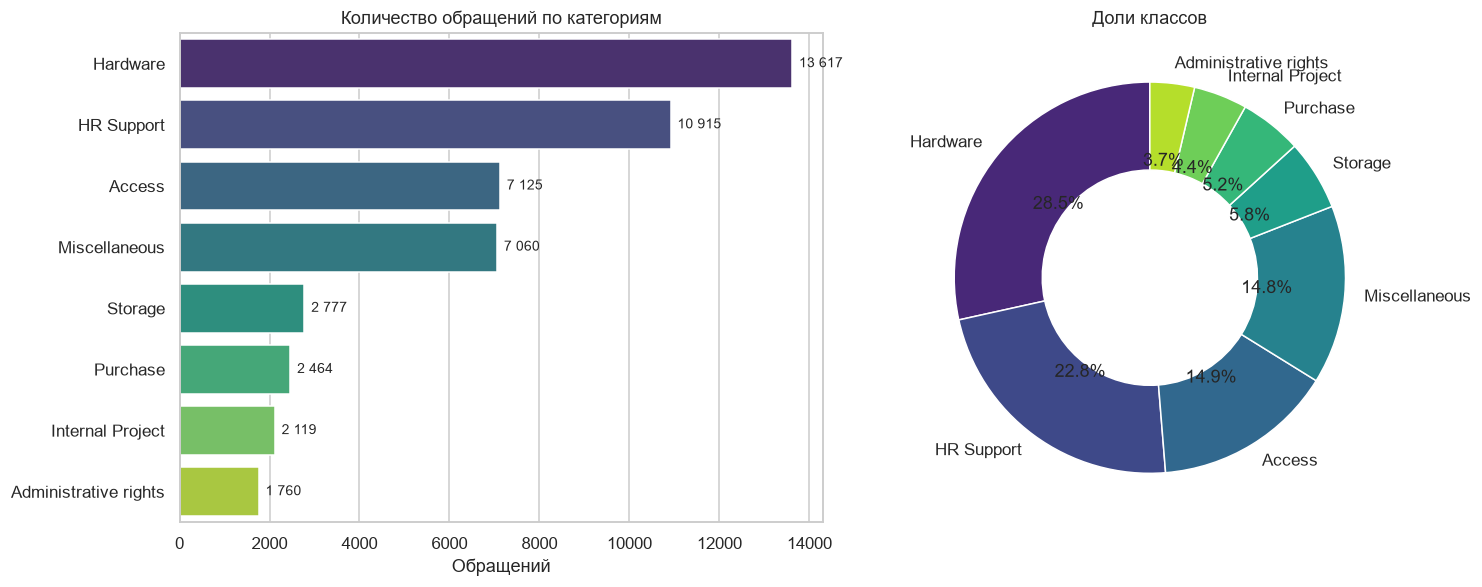

Соотношение самого частого и самого редкого класса: 7.7×


In [6]:
order = counts.index
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(x=counts.values, y=order, ax=axes[0], palette='viridis')
axes[0].set_title('Количество обращений по категориям')
axes[0].set_xlabel('Обращений')
axes[0].set_ylabel('')
for i, v in enumerate(counts.values):
    axes[0].text(v + 150, i, f'{v:,}'.replace(',', ' '), va='center', fontsize=9)

axes[1].pie(counts.values, labels=order, autopct='%1.1f%%', startangle=90,
            colors=sns.color_palette('viridis', len(order)),
            wedgeprops=dict(width=0.45, edgecolor='white'))
axes[1].set_title('Доли классов')

plt.tight_layout()
plt.savefig(REPORTS / 'eda_class_distribution.png', bbox_inches='tight', dpi=150)
plt.show()

imbalance = counts.max() / counts.min()
print(f'Соотношение самого частого и самого редкого класса: {imbalance:.1f}×')

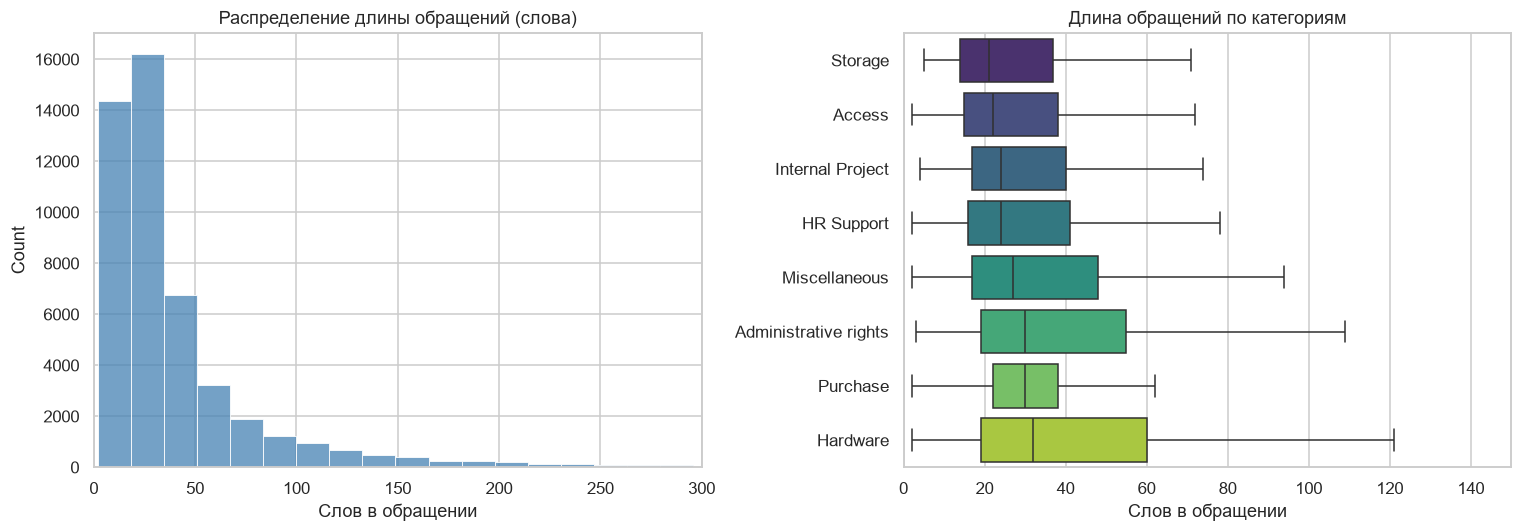

,mean,median,max
Topic_group,,,
Storage,34.4,21.0,497
Access,35.6,22.0,934
Internal Project,37.7,24.0,876
HR Support,37.8,24.0,817
Miscellaneous,43.0,27.0,953
Administrative rights,50.4,30.0,981
Purchase,34.9,30.0,418
Hardware,56.3,32.0,931


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['text_len_words'], bins=60, ax=axes[0], color='steelblue')
axes[0].set_xlim(0, 300)
axes[0].set_title('Распределение длины обращений (слова)')
axes[0].set_xlabel('Слов в обращении')

order_len = df.groupby(LABEL_COLUMN)['text_len_words'].median().sort_values().index
sns.boxplot(data=df, x='text_len_words', y=LABEL_COLUMN, order=order_len,
            ax=axes[1], showfliers=False, palette='viridis')
axes[1].set_xlim(0, 150)
axes[1].set_title('Длина обращений по категориям')
axes[1].set_xlabel('Слов в обращении')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig(REPORTS / 'eda_text_length.png', bbox_inches='tight', dpi=150)
plt.show()

display(df.groupby(LABEL_COLUMN)['text_len_words']
          .agg(['mean', 'median', 'max']).round(1)
          .sort_values('median'))

In [8]:
# Самые частые слова в «сырых» текстах по категориям (без предобработки, только для обзора)
from collections import Counter

def top_words(texts, n=8):
    words = Counter()
    for t in texts:
        words.update(re.findall(r'[a-zA-Z]{3,}', str(t).lower()))
    return [w for w, _ in words.most_common(n)]

rows = {cls: ', '.join(top_words(df.loc[df[LABEL_COLUMN] == cls, TEXT_COLUMN]))
        for cls in counts.index}
pd.DataFrame({'Топ-слова (сырой текст)': pd.Series(rows)})

,Топ-слова (сырой текст)
Hardware,"please, you, regards, for, hello, thank, sent,..."
HR Support,"please, thank, for, leaver, regards, hello, er..."
Access,"please, confluence, regards, hello, thanks, th..."
Miscellaneous,"please, change, for, regards, thank, hello, th..."
Storage,"please, mailbox, folder, access, wants, thank,..."
Purchase,"please, purchase, administrator, log, regards,..."
Internal Project,"please, code, thanks, regards, thank, setup, p..."
Administrative rights,"upgrade, please, you, for, regards, hello, upd..."


### Выводы по EDA

- **Размер и качество данных.** 47 837 обращений, две колонки: `Document` (текст) и `Topic_group` (метка).
  Пропусков и полных дубликатов нет — дополнительная чистка строк не требуется.
- **Классов восемь, дисбаланс заметный:** Hardware — 13 617 (28,5 %), HR Support — 10 915 (22,8 %),
  тогда как Administrative rights — 1 760 (3,7 %) и Internal Project — 2 119 (4,4 %).
  Соотношение крайних классов ≈ 7,7×, поэтому accuracy сама по себе неинформативна:
  основными метриками выбраны **F1-macro** и **F1-weighted**, а разбиение — стратифицированное.
- **Длина обращений.** В среднем ≈ 44 слова (медиана 26), распределение с длинным правым хвостом
  (максимум 981 слово). Есть 14 очень коротких обращений (< 3 слов); после очистки
  полностью опустели только 2 из них — итоговый датасет 47 835 строк.
- **Категории различаются по длине:** самые длинные обращения — Hardware (медиана 32 слова),
  самые короткие — Access и Storage (21–22 слова). Сама длина — слабый, но полезный сигнал.
- **Тексты уже частично анонимизированы** (встречается служебное слово `icon`, обрывки фраз),
  поэтому качество классификации будет ограничено шумом в данных.
- **Влияние на обучение:** из-за дисбаланса модель будет смещена в сторону Hardware и HR Support;
  это нужно учитывать при анализе ошибок и, при необходимости, балансировать классы
  через `class_weight='balanced'`.

## Шаг 3. Предобработка текста

Приведение к нижнему регистру, удаление URL, e-mail, пунктуации и цифр, удаление стоп-слов NLTK,
отбрасывание коротких токенов, лемматизация WordNet.

In [9]:
STOP_WORDS = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text: str) -> str:
    '''Очистка и нормализация текста обращения.'''
    if not isinstance(text, str):
        return ''
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)      # ссылки
    text = re.sub(r'\S+@\S+', ' ', text)             # e-mail
    text = re.sub(r'[^a-z\s]', ' ', text)            # цифры и пунктуация
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = [t for t in text.split() if t not in STOP_WORDS and len(t) > 2]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return ' '.join(tokens)

t0 = time.perf_counter()
df['clean_text'] = df[TEXT_COLUMN].apply(preprocess_text)
print(f'Предобработка заняла {time.perf_counter() - t0:.1f} c')

before = len(df)
df = df[df['clean_text'].str.len() > 0].reset_index(drop=True)
print(f'Удалено пустых после очистки: {before - len(df)}; осталось строк: {len(df):,}'.replace(',', ' '))
print()
print('Оригинал :', df[TEXT_COLUMN].iloc[0][:180])
print('Очищено  :', df['clean_text'].iloc[0][:180])

Предобработка заняла 4.9 c
Удалено пустых после очистки: 2; осталось строк: 47 835

Оригинал : connection with icon icon dear please setup icon per icon engineers please let other details needed thanks lead
Очищено  : connection icon icon dear please setup icon per icon engineer please let detail needed thanks lead


In [10]:
# Сколько информации сохранилось после очистки
df['clean_len_words'] = df['clean_text'].str.split().str.len()
display(df[['text_len_words', 'clean_len_words']].describe().round(1))
print('Средняя доля сохранённых слов:',
      round(df['clean_len_words'].sum() / df['text_len_words'].sum() * 100, 1), '%')

,text_len_words,clean_len_words
count,47835.0,47835.0
mean,43.6,35.3
std,56.7,45.8
min,2.0,1.0
25%,17.0,14.0
50%,26.0,22.0
75%,46.0,37.0
max,981.0,830.0


Средняя доля сохранённых слов: 81.1 %


## Шаг 4. Разбиение на train/test

Пропорция 80/20, стратификация по метке класса.

In [11]:
X = df['clean_text']
y = df[LABEL_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f'train: {len(X_train):,}'.replace(',', ' '), '| test:', f'{len(X_test):,}'.replace(',', ' '))

dist = pd.DataFrame({
    'train, %': y_train.value_counts(normalize=True).mul(100).round(2),
    'test, %': y_test.value_counts(normalize=True).mul(100).round(2),
}).loc[y.value_counts().index]
dist['Δ, п.п.'] = (dist['train, %'] - dist['test, %']).round(3)
display(dist)

train: 38 268 | test: 9 567


,"train, %","test, %","Δ, п.п."
Topic_group,,,
Hardware,28.47,28.46,0.01
HR Support,22.82,22.82,0.00
Access,14.89,14.89,0.00
Miscellaneous,14.76,14.76,0.00
Storage,5.81,5.80,0.01
Purchase,5.15,5.15,0.00
Internal Project,4.43,4.43,0.00
Administrative rights,3.68,3.68,0.00


## Шаг 5. Векторизация и обучение классических моделей

Каждая модель — единый `sklearn.pipeline.Pipeline` из `TfidfVectorizer` и классификатора:
векторизатор обучается только на train, что исключает утечку данных.

Каждый запуск логируется в MLflow: параметры (`mlflow.log_param`), метрики (`mlflow.log_metric`),
отчёт и матрица ошибок как артефакты.

In [12]:
MLFLOW_DB = Path('mlflow.db').resolve()
mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DB.as_posix()}')
EXPERIMENT_NAME = 'ticket-classification'
experiment = mlflow.set_experiment(EXPERIMENT_NAME)

print('Tracking URI :', mlflow.get_tracking_uri())
print('Эксперимент  :', experiment.name)

2026/11/03 21:49:33 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/03 21:49:33 INFO mlflow.store.db.utils: Updating database tables


2026/11/03 21:49:34 INFO mlflow.tracking.fluent: Experiment with name 'ticket-classification' does not exist. Creating a new experiment.


Tracking URI : sqlite:///C:/Users/MIXA/Desktop/AI/Нитология AI агенты/AI/edit_files/aiml-5 Итоговая работа/mlflow.db
Эксперимент  : ticket-classification


In [13]:
TFIDF_PARAMS = dict(
    max_features=50_000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)

MODELS = {
    'LogisticRegression': Pipeline([
        ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
        ('clf', LogisticRegression(C=5.0, max_iter=1000, class_weight='balanced',
                                   random_state=RANDOM_STATE)),
    ]),
    'LinearSVC': Pipeline([
        ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
        ('clf', LinearSVC(C=0.5, class_weight='balanced', random_state=RANDOM_STATE)),
    ]),
    'ComplementNB': Pipeline([
        ('tfidf', TfidfVectorizer(**TFIDF_PARAMS)),
        ('clf', ComplementNB(alpha=0.3)),
    ]),
}

for name, pipe in MODELS.items():
    print(name, '->', [step for step, _ in pipe.steps])

LogisticRegression -> ['tfidf', 'clf']
LinearSVC -> ['tfidf', 'clf']
ComplementNB -> ['tfidf', 'clf']


=== Обучение: LogisticRegression ===


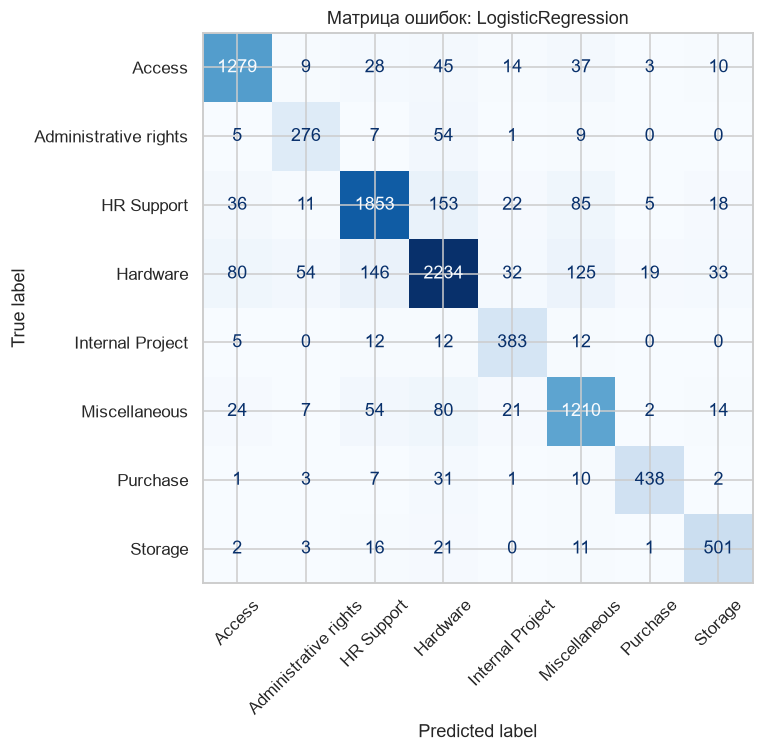

2026/11/03 21:49:45 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


accuracy=0.8544  F1-macro=0.8554  F1-weighted=0.8545  (8.4 c)
run_id: 78d684d21c56452fb145cbf05986f1ed
=== Обучение: LinearSVC ===


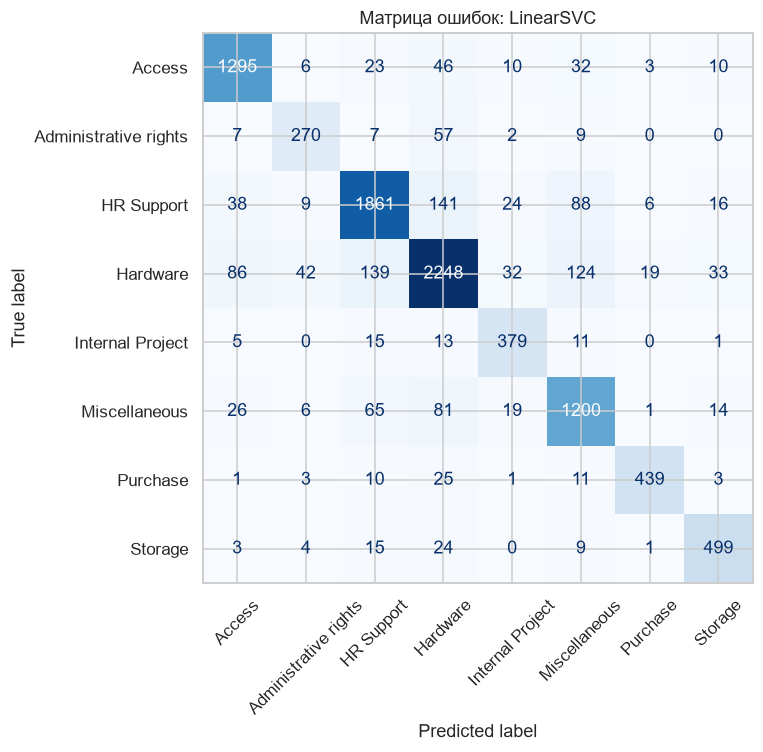

2026/11/03 21:49:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


accuracy=0.8562  F1-macro=0.8567  F1-weighted=0.8561  (2.3 c)
run_id: f5981f31ddb9432da05607d9850005bd
=== Обучение: ComplementNB ===


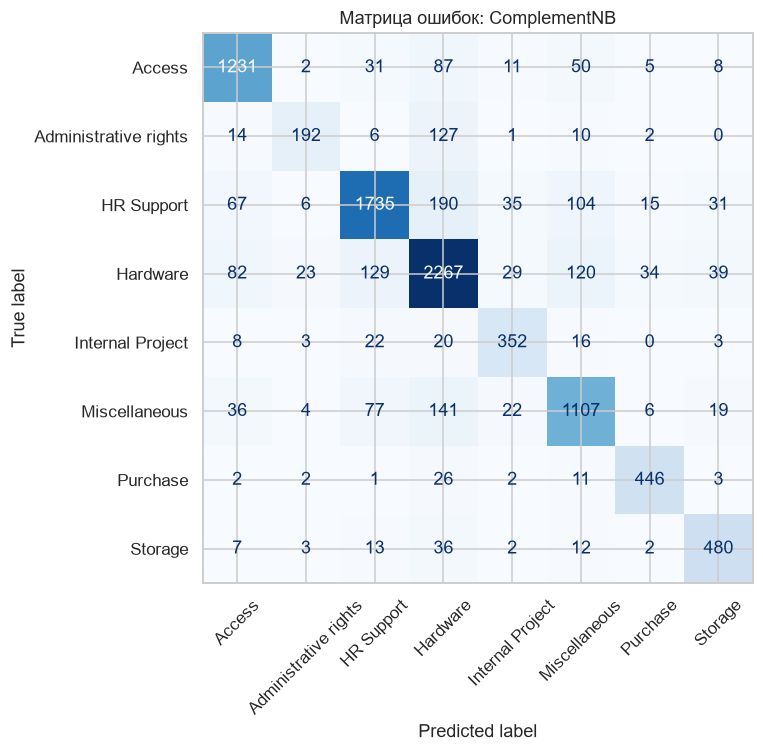

2026/11/03 21:49:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


accuracy=0.8163  F1-macro=0.8074  F1-weighted=0.8154  (1.6 c)
run_id: 83bf731dcab1450d835881b15cdd313b


In [14]:
def evaluate(y_true, y_pred):
    '''Основные метрики для многоклассовой задачи.'''
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'precision_weighted': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'f1_weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
    }

classical_results = {}
classical_preds = {}
trained_pipelines = {}

for model_name, pipe in MODELS.items():
    print(f'=== Обучение: {model_name} ===')
    with mlflow.start_run(run_name=model_name) as run:
        t0 = time.perf_counter()
        pipe.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - t0
        pred = pipe.predict(X_test)
        fit_train = pipe.score(X_train, y_train)

        metrics = evaluate(y_test, pred)
        pred_seconds = time.perf_counter() - t0 - fit_seconds

        # --- параметры ---
        tfidf = pipe.named_steps['tfidf']
        clf = pipe.named_steps['clf']
        mlflow.log_param('model_family', 'classical')
        mlflow.log_param('classifier', model_name)
        mlflow.log_param('tfidf_max_features', tfidf.max_features)
        mlflow.log_param('tfidf_ngram_range', str(tfidf.ngram_range))
        mlflow.log_param('tfidf_min_df', tfidf.min_df)
        mlflow.log_param('tfidf_sublinear_tf', tfidf.sublinear_tf)
        mlflow.log_param('vocabulary_size', len(tfidf.vocabulary_))
        mlflow.log_param('random_state', RANDOM_STATE)
        for pname, pvalue in clf.get_params().items():
            if pname == 'random_state':
                continue
            mlflow.log_param(f'clf__{pname}', str(pvalue))
        mlflow.log_param('fit_seconds', round(fit_seconds, 2))
        mlflow.log_param('predict_seconds', round(pred_seconds, 2))
        mlflow.log_param('train_accuracy', round(float(fit_train), 4))

        # --- метрики ---
        mlflow.log_metrics({k: round(float(v), 4) for k, v in metrics.items()})

        # --- артефакты ---
        report_txt = classification_report(y_test, pred, digits=4)
        (REPORTS / f'report_{model_name}.txt').write_text(report_txt, encoding='utf-8')
        mlflow.log_text(report_txt, f'report_{model_name}.txt')

        fig, ax = plt.subplots(figsize=(8.5, 7))
        ConfusionMatrixDisplay.from_predictions(
            y_test, pred, xticks_rotation=45, ax=ax, colorbar=False, cmap='Blues'
        )
        ax.set_title(f'Матрица ошибок: {model_name}')
        plt.tight_layout()
        cm_path = REPORTS / f'confusion_{model_name}.png'
        plt.savefig(cm_path, bbox_inches='tight', dpi=150)
        plt.show()
        mlflow.log_artifact(str(cm_path))

        # модель
        mlflow.sklearn.log_model(pipe, name='model', serialization_format='pickle')

        classical_results[model_name] = {
            **metrics,
            'fit_seconds': fit_seconds,
            'train_accuracy': float(fit_train),
            'vocabulary_size': len(tfidf.vocabulary_),
        }
        classical_preds[model_name] = pred
        trained_pipelines[model_name] = pipe

        print(f'accuracy={metrics["accuracy"]:.4f}  F1-macro={metrics["f1_macro"]:.4f}  '
              f'F1-weighted={metrics["f1_weighted"]:.4f}  ({fit_seconds:.1f} c)')
        print(f'run_id: {run.info.run_id}')

## Шаг 6. Нейросетевая модель — MLP на PyTorch

Тексты векторизуются тем же TF-IDF-подходом (ограничение 5 000 признаков, чтобы плотные
тензоры помещались в память). В отличие от шаблона, разреженная матрица не разворачивается
целиком: `Dataset` отдаёт по одной строке, а в плотный тензор строка превращается в `collate_fn`
непосредственно перед подачей в сеть — это экономит сотни мегабайт ОЗУ.

Архитектура: `5000 → 256 → ReLU → Dropout(0.3) → 128 → ReLU → Dropout(0.2) → 8`.
Функция потерь — `CrossEntropyLoss`, оптимизатор — Adam.

In [15]:
# 1. Кодирование целевой переменной
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = len(le.classes_)
print('Классы:', list(le.classes_))

# 2. Векторизация (тот же подход, но меньше признаков — для плотных тензоров)
tfidf_mlp = TfidfVectorizer(
    max_features=5_000, ngram_range=(1, 2), min_df=2, sublinear_tf=True
)
X_train_sp = tfidf_mlp.fit_transform(X_train)
X_test_sp = tfidf_mlp.transform(X_test)
print('TF-IDF для MLP:', X_train_sp.shape, '| плотный эквивалент:',
      f'{X_train_sp.shape[0] * X_train_sp.shape[1] * 4 / 1024**2:.0f} МБ')

# 3. Dataset поверх разреженной матрицы
class SparseTextDataset(Dataset):
    def __init__(self, matrix, labels):
        self.matrix = matrix.tocsr()
        self.labels = np.asarray(labels)

    def __len__(self):
        return self.matrix.shape[0]

    def __getitem__(self, idx):
        row = torch.from_numpy(self.matrix[idx].toarray().ravel().astype('float32'))
        return row, int(self.labels[idx])

def collate_dense(batch):
    features = torch.stack([item[0] for item in batch])
    labels = torch.tensor([item[1] for item in batch], dtype=torch.long)
    return features, labels

train_dataset = SparseTextDataset(X_train_sp, y_train_enc)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, collate_fn=collate_dense)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)

Классы: ['Access', 'Administrative rights', 'HR Support', 'Hardware', 'Internal Project', 'Miscellaneous', 'Purchase', 'Storage']


TF-IDF для MLP: (38268, 5000) | плотный эквивалент: 730 МБ
Устройство: cpu


In [16]:
class TicketMLP(nn.Module):
    '''Полносвязная сеть для многоклассовой классификации текстов.'''

    def __init__(self, input_dim, num_classes, hidden1=256, hidden2=128, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Dropout(dropout * 0.67),
            nn.Linear(hidden2, num_classes),
        )

    def forward(self, x):
        return self.net(x)

mlp = TicketMLP(input_dim=X_train_sp.shape[1], num_classes=num_classes).to(device)
print(mlp)
print('Параметров:', sum(p.numel() for p in mlp.parameters()))

TicketMLP(
  (net): Sequential(
    (0): Linear(in_features=5000, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.201, inplace=False)
    (6): Linear(in_features=128, out_features=8, bias=True)
  )
)
Параметров: 1314184


Эпоха 1/8 | train loss 0.8959 acc 0.6909 | test loss 0.4693 acc 0.8377


Эпоха 2/8 | train loss 0.4000 acc 0.8641 | test loss 0.4424 acc 0.8448


Эпоха 3/8 | train loss 0.3160 acc 0.8917 | test loss 0.4568 acc 0.8442


Эпоха 4/8 | train loss 0.2630 acc 0.9089 | test loss 0.4739 acc 0.8400


Эпоха 5/8 | train loss 0.2152 acc 0.9264 | test loss 0.5094 acc 0.8393


Эпоха 6/8 | train loss 0.1765 acc 0.9407 | test loss 0.5510 acc 0.8343


Эпоха 7/8 | train loss 0.1388 acc 0.9527 | test loss 0.5954 acc 0.8346


Эпоха 8/8 | train loss 0.1125 acc 0.9639 | test loss 0.6404 acc 0.8358


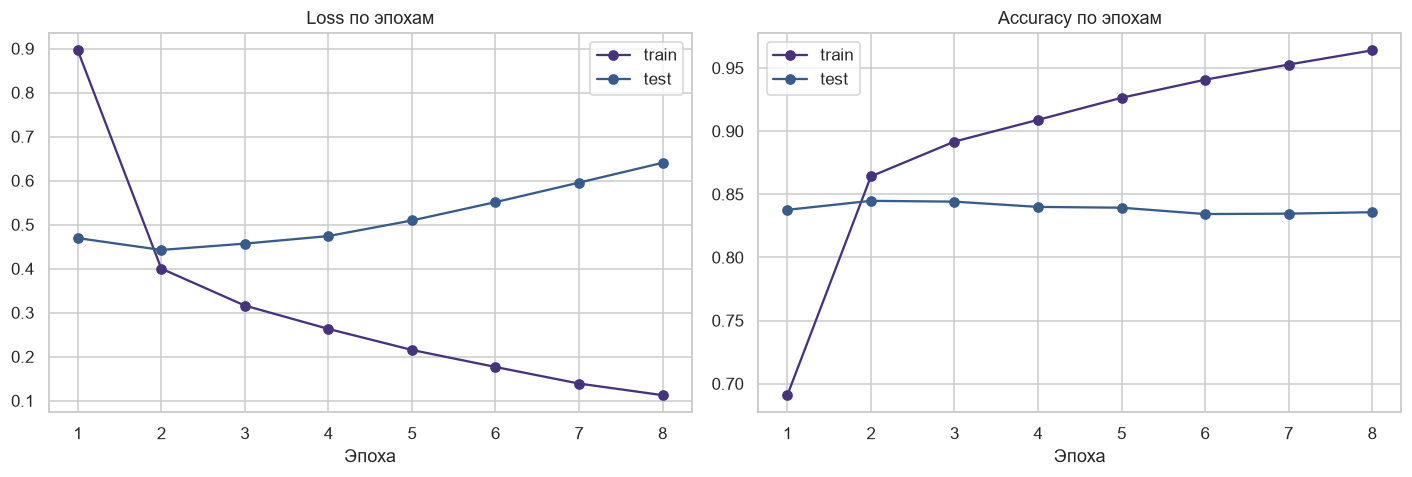

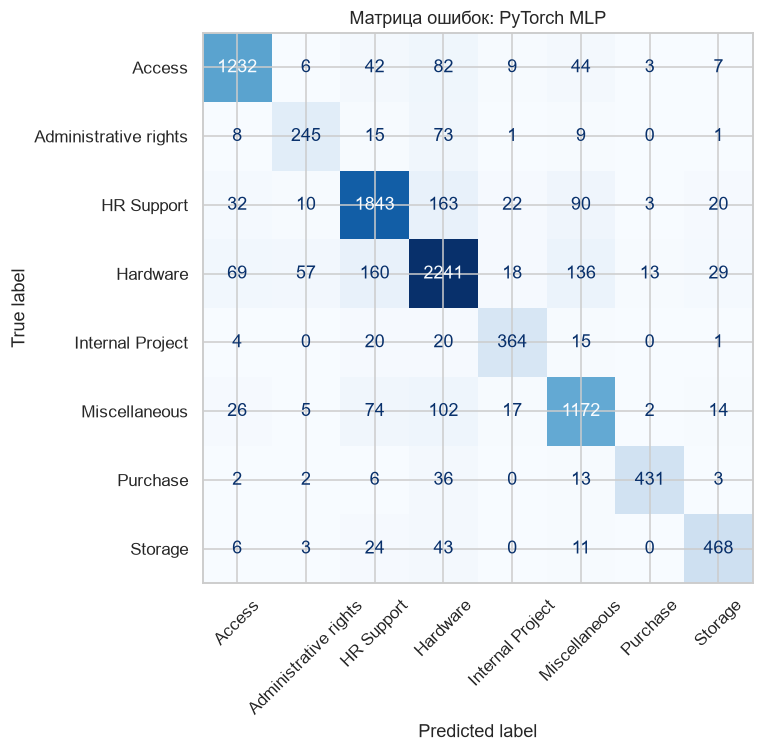

2026/11/03 21:50:25 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.


2026/11/03 21:50:25 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.15.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


2026/11/03 21:50:28 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cpu) contains a local version label (+cpu). MLflow logged a pip requirement for this package as 'torch==2.15.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.



MLP: accuracy=0.8358  F1-macro=0.8356  F1-weighted=0.8361  (19.9 c)
run_id: c5ae35f759ce47269730630045b1daa5


In [17]:
EPOCHS = 8
BATCH_SIZE = 128
LR = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=LR)

X_test_tensor = torch.from_numpy(X_test_sp.toarray().astype('float32')).to(device)
y_test_tensor = torch.from_numpy(y_test_enc).to(device)

history = {'epoch': [], 'train_loss': [], 'train_acc': [], 'test_acc': [], 'test_loss': []}

with mlflow.start_run(run_name='PyTorch_MLP') as mlp_run:
    mlflow.log_param('model_family', 'neural_network')
    mlflow.log_param('classifier', 'TicketMLP')
    mlflow.log_param('tfidf_max_features', tfidf_mlp.max_features)
    mlflow.log_param('tfidf_ngram_range', str(tfidf_mlp.ngram_range))
    mlflow.log_param('tfidf_min_df', tfidf_mlp.min_df)
    mlflow.log_param('vocabulary_size', len(tfidf_mlp.vocabulary_))
    mlflow.log_param('hidden_dims', '256-128')
    mlflow.log_param('dropout', 0.3)
    mlflow.log_param('epochs', EPOCHS)
    mlflow.log_param('batch_size', BATCH_SIZE)
    mlflow.log_param('learning_rate', LR)
    mlflow.log_param('optimizer', 'Adam')
    mlflow.log_param('loss', 'CrossEntropyLoss')
    mlflow.log_param('device', str(device))
    mlflow.log_param('trainable_params', sum(p.numel() for p in mlp.parameters()))

    t0 = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        mlp.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = mlp(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * yb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += yb.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        mlp.eval()
        with torch.no_grad():
            test_logits = mlp(X_test_tensor)
            test_loss = criterion(test_logits, y_test_tensor).item()
            test_pred_enc = test_logits.argmax(dim=1).cpu().numpy()
        test_acc = accuracy_score(y_test_enc, test_pred_enc)

        history['epoch'].append(epoch)
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        mlflow.log_metric('train_loss', round(train_loss, 4), step=epoch)
        mlflow.log_metric('train_accuracy', round(train_acc, 4), step=epoch)
        mlflow.log_metric('test_loss', round(test_loss, 4), step=epoch)
        mlflow.log_metric('test_accuracy', round(test_acc, 4), step=epoch)

        print(f'Эпоха {epoch}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.4f} '
              f'| test loss {test_loss:.4f} acc {test_acc:.4f}')

    mlp_fit_seconds = time.perf_counter() - t0

    # предсказания и метрики
    mlp_pred = le.inverse_transform(test_pred_enc)
    mlp_metrics = evaluate(y_test, mlp_pred)
    mlflow.log_metrics({k: round(float(v), 4) for k, v in mlp_metrics.items()})
    mlflow.log_param('fit_seconds', round(mlp_fit_seconds, 2))

    report_mlp = classification_report(y_test, mlp_pred, digits=4)
    (REPORTS / 'report_PyTorch_MLP.txt').write_text(report_mlp, encoding='utf-8')
    mlflow.log_text(report_mlp, 'report_PyTorch_MLP.txt')

    # кривые обучения
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(history['epoch'], history['train_loss'], marker='o', label='train')
    axes[0].plot(history['epoch'], history['test_loss'], marker='o', label='test')
    axes[0].set_title('Loss по эпохам'); axes[0].set_xlabel('Эпоха'); axes[0].legend()
    axes[1].plot(history['epoch'], history['train_acc'], marker='o', label='train')
    axes[1].plot(history['epoch'], history['test_acc'], marker='o', label='test')
    axes[1].set_title('Accuracy по эпохам'); axes[1].set_xlabel('Эпоха'); axes[1].legend()
    plt.tight_layout()
    curves_path = REPORTS / 'mlp_training_curves.png'
    plt.savefig(curves_path, bbox_inches='tight', dpi=150)
    plt.show()
    mlflow.log_artifact(str(curves_path))

    # матрица ошибок
    fig, ax = plt.subplots(figsize=(8.5, 7))
    ConfusionMatrixDisplay.from_predictions(
        y_test, mlp_pred, xticks_rotation=45, ax=ax, colorbar=False, cmap='Blues'
    )
    ax.set_title('Матрица ошибок: PyTorch MLP')
    plt.tight_layout()
    mlp_cm_path = REPORTS / 'confusion_PyTorch_MLP.png'
    plt.savefig(mlp_cm_path, bbox_inches='tight', dpi=150)
    plt.show()
    mlflow.log_artifact(str(mlp_cm_path))

    # модель и словарь TF-IDF
    mlflow.pytorch.log_model(mlp.cpu(), name='model', serialization_format='pickle')
    mlp.to(device)

    print()
    print(f'MLP: accuracy={mlp_metrics["accuracy"]:.4f}  F1-macro={mlp_metrics["f1_macro"]:.4f}  '
          f'F1-weighted={mlp_metrics["f1_weighted"]:.4f}  ({mlp_fit_seconds:.1f} c)')
    print('run_id:', mlp_run.info.run_id)

## Шаг 7. Оценка качества моделей

Подробные отчёты `classification_report` (precision, recall, F1 по каждому классу + macro/weighted),
матрицы ошибок и сводная таблица.

In [18]:
results = {**classical_results,
           'PyTorch_MLP': {**mlp_metrics, 'fit_seconds': mlp_fit_seconds,
                           'train_accuracy': history['train_acc'][-1],
                           'vocabulary_size': len(tfidf_mlp.vocabulary_)}}

preds = {**classical_preds, 'PyTorch_MLP': mlp_pred}

for name in results:
    print('=' * 70)
    print(name)
    print('=' * 70)
    print(classification_report(y_test, preds[name], digits=4))

LogisticRegression
                       precision    recall  f1-score   support

               Access     0.8932    0.8975    0.8953      1425
Administrative rights     0.7603    0.7841    0.7720       352
           HR Support     0.8728    0.8488    0.8607      2183
             Hardware     0.8494    0.8204    0.8347      2723
     Internal Project     0.8080    0.9033    0.8530       424
        Miscellaneous     0.8072    0.8569    0.8313      1412
             Purchase     0.9359    0.8884    0.9116       493
              Storage     0.8668    0.9027    0.8844       555

             accuracy                         0.8544      9567
            macro avg     0.8492    0.8628    0.8554      9567
         weighted avg     0.8554    0.8544    0.8545      9567

LinearSVC
                       precision    recall  f1-score   support

               Access     0.8864    0.9088    0.8974      1425
Administrative rights     0.7941    0.7670    0.7803       352
           HR Support 

                       precision    recall  f1-score   support

               Access     0.8507    0.8639    0.8572      1425
Administrative rights     0.8170    0.5455    0.6542       352
           HR Support     0.8615    0.7948    0.8268      2183
             Hardware     0.7833    0.8325    0.8072      2723
     Internal Project     0.7753    0.8302    0.8018       424
        Miscellaneous     0.7741    0.7840    0.7790      1412
             Purchase     0.8745    0.9047    0.8893       493
              Storage     0.8233    0.8649    0.8436       555

             accuracy                         0.8163      9567
            macro avg     0.8200    0.8025    0.8074      9567
         weighted avg     0.8177    0.8163    0.8154      9567



PyTorch_MLP
                       precision    recall  f1-score   support

               Access     0.8934    0.8646    0.8787      1425
Administrative rights     0.7470    0.6960    0.7206       352
           HR Support     0.8439    0.8443    0.8441      2183
             Hardware     0.8120    0.8230    0.8174      2723
     Internal Project     0.8445    0.8585    0.8515       424
        Miscellaneous     0.7866    0.8300    0.8077      1412
             Purchase     0.9535    0.8742    0.9122       493
              Storage     0.8619    0.8432    0.8525       555

             accuracy                         0.8358      9567
            macro avg     0.8428    0.8292    0.8356      9567
         weighted avg     0.8369    0.8358    0.8361      9567



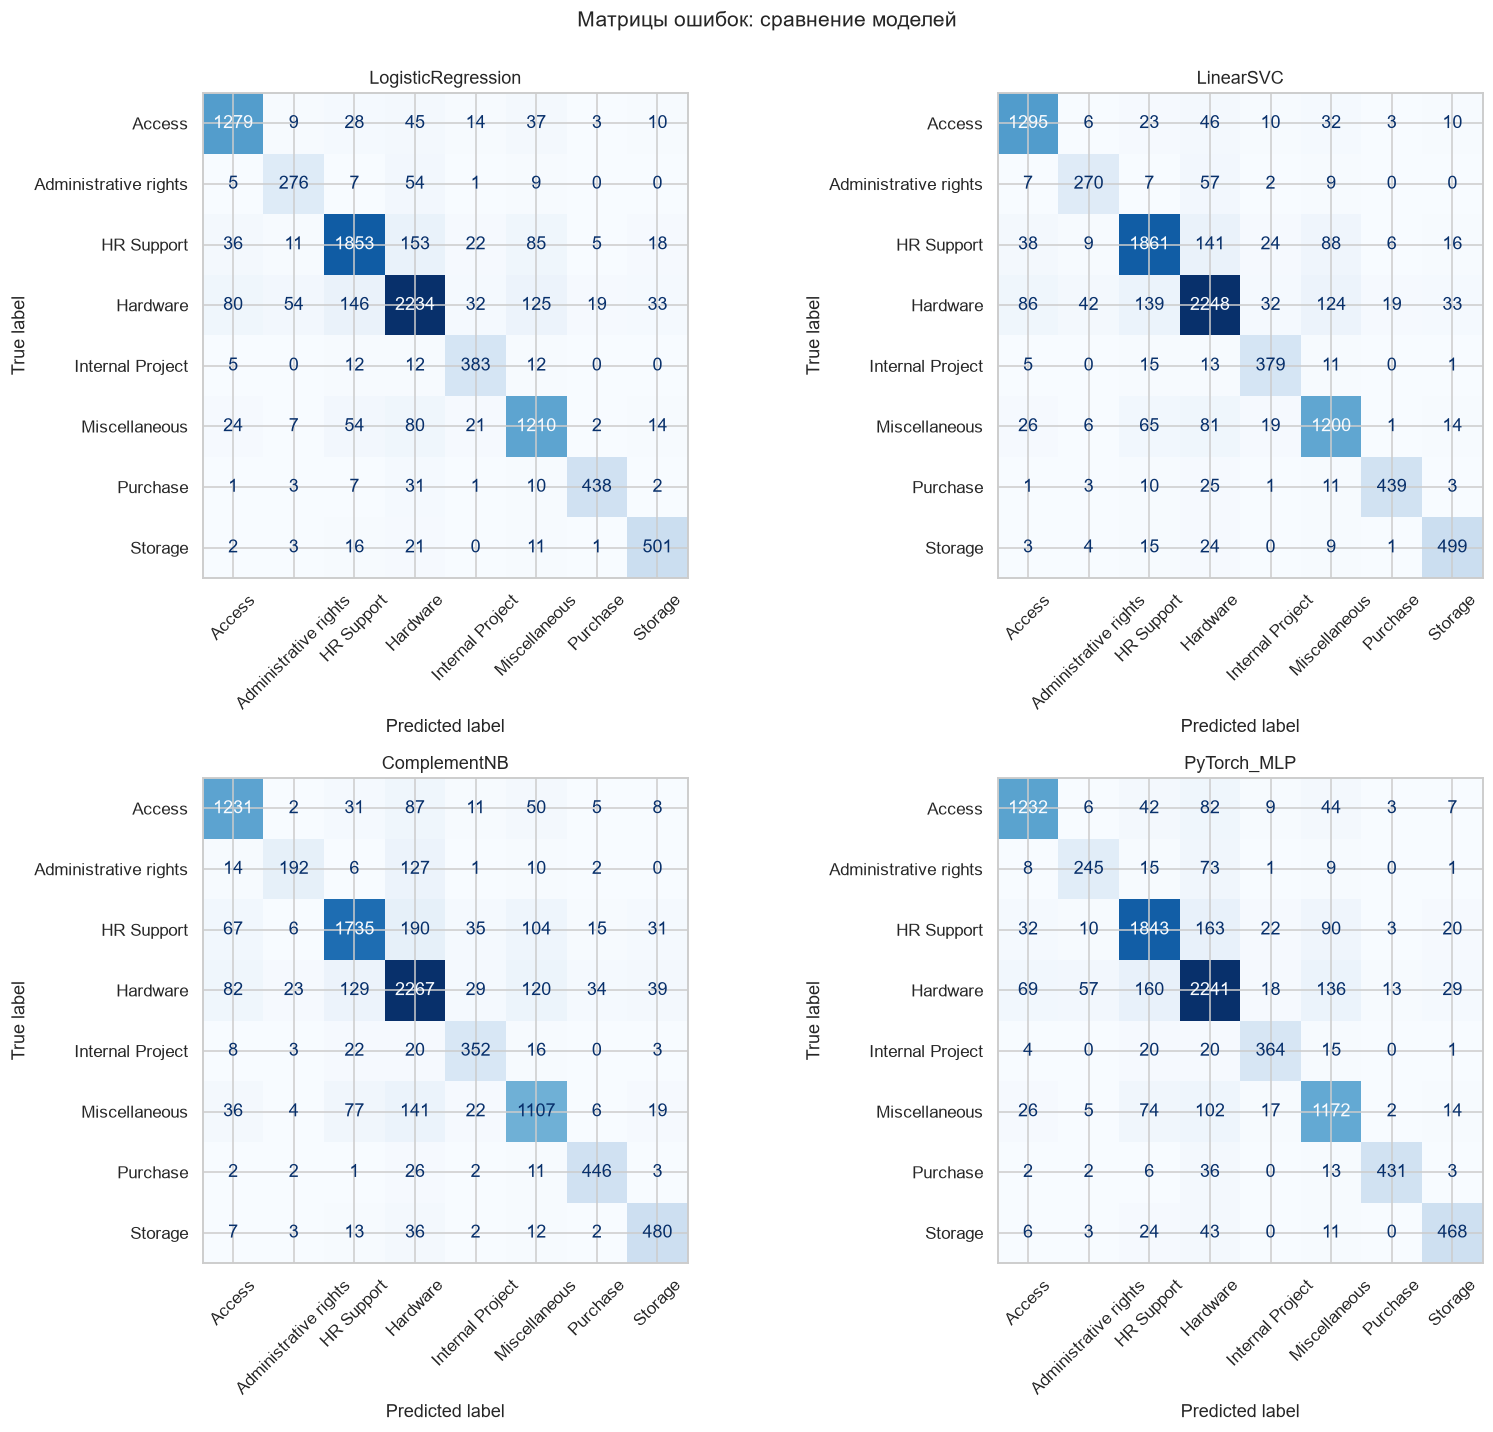

In [19]:
# Матрицы ошибок всех моделей на одной картинке
n_models = len(preds)
fig, axes = plt.subplots(2, 2, figsize=(15, 13))
axes = axes.ravel()
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, xticks_rotation=45, ax=ax, colorbar=False, cmap='Blues'
    )
    ax.set_title(name)
for ax in axes[n_models:]:
    ax.axis('off')
plt.suptitle('Матрицы ошибок: сравнение моделей', fontsize=14, y=1.0)
plt.tight_layout()
plt.savefig(REPORTS / 'confusion_all_models.png', bbox_inches='tight', dpi=150)
plt.show()

In [20]:
summary = pd.DataFrame(results).T
summary = summary[['accuracy', 'precision_macro', 'recall_macro', 'f1_macro',
                   'precision_weighted', 'recall_weighted', 'f1_weighted',
                   'train_accuracy', 'fit_seconds']]
summary = summary.round(4).sort_values('f1_macro', ascending=False)
summary.index.name = 'Модель'
summary.to_csv(REPORTS / 'model_comparison.csv', encoding='utf-8')
display(summary)

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,train_accuracy,fit_seconds
Модель,,,,,,,,,
LinearSVC,0.8562,0.8535,0.8609,0.8567,0.8568,0.8562,0.8561,0.9701,2.2845
LogisticRegression,0.8544,0.8492,0.8628,0.8554,0.8554,0.8544,0.8545,0.9665,8.3918
PyTorch_MLP,0.8358,0.8428,0.8292,0.8356,0.8369,0.8358,0.8361,0.9639,19.8620
ComplementNB,0.8163,0.8200,0.8025,0.8074,0.8177,0.8163,0.8154,0.8912,1.5709


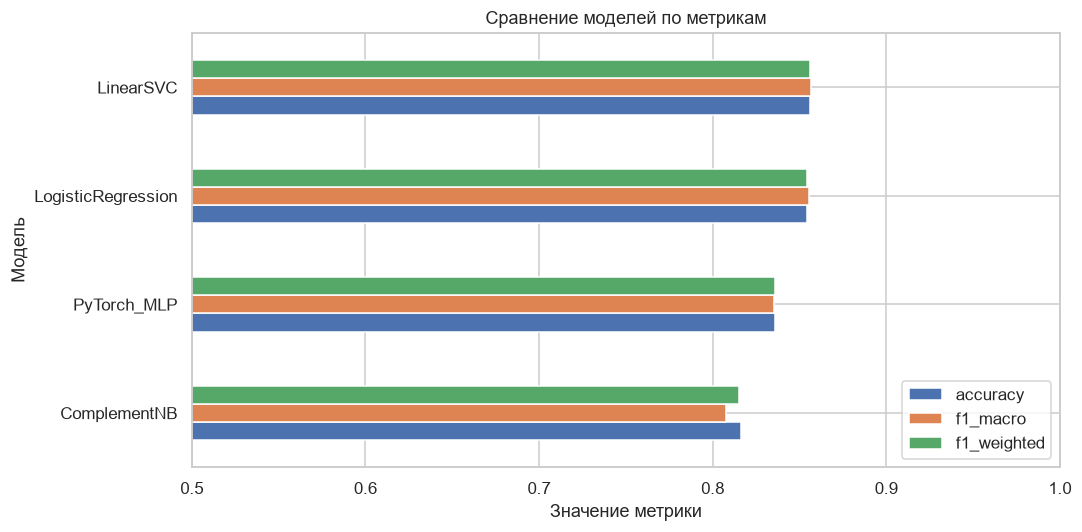

In [21]:
# Наглядное сравнение F1
plot_df = summary[['accuracy', 'f1_macro', 'f1_weighted']].sort_values('f1_macro')
plot_df.plot(kind='barh', figsize=(10, 5), color=['#4c72b0', '#dd8452', '#55a868'])
plt.title('Сравнение моделей по метрикам')
plt.xlabel('Значение метрики')
plt.xlim(0.5, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(REPORTS / 'model_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

In [22]:
# MLflow: все запуски эксперимента
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME],
                           order_by=['metrics.f1_macro DESC'])
cols = ['tags.mlflow.runName', 'params.classifier', 'metrics.accuracy',
        'metrics.f1_macro', 'metrics.f1_weighted']
display(runs[cols].rename(columns={
    'tags.mlflow.runName': 'run', 'params.classifier': 'classifier',
    'metrics.accuracy': 'accuracy', 'metrics.f1_macro': 'f1_macro',
    'metrics.f1_weighted': 'f1_weighted',
}))

,run,classifier,accuracy,f1_macro,f1_weighted
0,LinearSVC,LinearSVC,0.8562,0.8567,0.8561
1,LogisticRegression,LogisticRegression,0.8544,0.8554,0.8545
2,PyTorch_MLP,TicketMLP,0.8358,0.8356,0.8361
3,ComplementNB,ComplementNB,0.8163,0.8074,0.8154


## Шаг 8. Анализ ошибок лучшей модели

Разберём, какие классы предсказываются хуже всего и какие пары классов модель путает.

In [23]:
BEST_MODEL = summary.index[0]
best_pred = preds[BEST_MODEL]
print('Лучшая модель по F1-macro:', BEST_MODEL)

report_dict = classification_report(y_test, best_pred, output_dict=True, zero_division=0)
per_class = (pd.DataFrame(report_dict).T
             .loc[le.classes_ if BEST_MODEL == 'PyTorch_MLP' else counts.index]
             [['precision', 'recall', 'f1-score', 'support']]
             .astype(float).round(4).sort_values('f1-score'))
per_class.index.name = 'Класс'
display(per_class)

Лучшая модель по F1-macro: LinearSVC


,precision,recall,f1-score,support
Класс,,,,
Administrative rights,0.7941,0.7670,0.7803,352.0
Miscellaneous,0.8086,0.8499,0.8287,1412.0
Hardware,0.8531,0.8256,0.8391,2723.0
Internal Project,0.8116,0.8939,0.8507,424.0
HR Support,0.8717,0.8525,0.8620,2183.0
Storage,0.8663,0.8991,0.8824,555.0
Access,0.8864,0.9088,0.8974,1425.0
Purchase,0.9360,0.8905,0.9127,493.0


In [24]:
cm = confusion_matrix(y_test, best_pred, labels=per_class.index)
cm_df = pd.DataFrame(cm, index=per_class.index, columns=per_class.index)

# самые частые пары «истинный → предсказанный» (без диагонали)
pairs = []
for true_cls in cm_df.index:
    for pred_cls in cm_df.columns:
        if true_cls != pred_cls and cm_df.loc[true_cls, pred_cls] > 0:
            pairs.append((true_cls, pred_cls, int(cm_df.loc[true_cls, pred_cls])))
pairs_df = pd.DataFrame(pairs, columns=['истинный класс', 'предсказан', 'ошибок'])
pairs_df = pairs_df.sort_values('ошибок', ascending=False).head(10)
print('Топ-10 перепутанных пар классов:')
display(pairs_df.reset_index(drop=True))

Топ-10 перепутанных пар классов:


,истинный класс,предсказан,ошибок
0,HR Support,Hardware,141
1,Hardware,HR Support,139
2,Hardware,Miscellaneous,124
3,HR Support,Miscellaneous,88
4,Hardware,Access,86
5,Miscellaneous,Hardware,81
6,Miscellaneous,HR Support,65
7,Administrative rights,Hardware,57
8,Access,Hardware,46
9,Hardware,Administrative rights,42


In [25]:
# Примеры ошибок лучшей модели
errors = X_test[y_test.values != best_pred].copy()
errors_df = pd.DataFrame({
    'текст': errors.str.slice(0, 200).values,
    'истинный класс': y_test[y_test.values != best_pred].values,
    'предсказано': best_pred[y_test.values != best_pred],
})
print(f'Всего ошибок: {len(errors_df):,} из {len(y_test):,}'.replace(',', ' '))
display(errors_df.sample(8, random_state=RANDOM_STATE))

Всего ошибок: 1 376 из 9 567


,текст,истинный класс,предсказано
503,read access discipline architecture wednesday ...,Miscellaneous,Hardware
67,server audit decommission hello please order d...,Miscellaneous,Hardware
842,access internal network hello working location...,Hardware,Storage
643,bucket internal project thursday bucket hello ...,HR Support,Internal Project
240,modify ibm service thursday modify ibm user ad...,Miscellaneous,Access
543,friday dear please provide recently requested ...,Hardware,HR Support
432,retrieval tuesday lite black floor phone repla...,Hardware,Purchase
570,notification thursday please include recipient...,Purchase,Miscellaneous


In [26]:
# Доля ошибок по классам
err_by_class = pd.DataFrame({
    'объектов': y_test.value_counts(),
    'ошибок': pd.Series(y_test.values != best_pred, index=y_test.index).groupby(y_test).sum(),
})
err_by_class['доля ошибок, %'] = (err_by_class['ошибок'] / err_by_class['объектов'] * 100).round(2)
err_by_class = err_by_class.sort_values('доля ошибок, %', ascending=False)
err_by_class.index.name = 'Класс'
display(err_by_class)

,объектов,ошибок,"доля ошибок, %"
Класс,,,
Administrative rights,352,82,23.30
Hardware,2723,475,17.44
Miscellaneous,1412,212,15.01
HR Support,2183,322,14.75
Purchase,493,54,10.95
Internal Project,424,45,10.61
Storage,555,56,10.09
Access,1425,130,9.12


## Шаг 9. Выводы

### 9.1. Сравнение моделей

| Модель | Accuracy | F1-macro | F1-weighted |
|---|---|---|---|
| LogisticRegression | 0.8544 | 0.8554 | 0.8545 |
| **LinearSVC** | **0.8562** | **0.8567** | **0.8561** |
| ComplementNB | 0.8163 | 0.8074 | 0.8154 |
| PyTorch MLP | 0.8358 | 0.8356 | 0.8361 |

*(точные значения — в сводной таблице выше и в `reports/model_comparison.csv`)*

**Лучшая модель — LinearSVC.** Она даёт наивысшие accuracy (0,8562) и F1-macro (0,8567)
и обучается за 2 секунды. Отрыв от логистической регрессии невелик (0,0013 по F1-macro —
около 15 объектов на тестовой выборке) и лежит в пределах статистической погрешности,
однако LinearSVC выигрывает и по скорости, и по F1 почти на всех классах, поэтому выбран он.
Причина в характере данных: TF-IDF по 50 000 признакам и 8 классам — почти линейно разделимая
задача с разреженными векторами; SVM с линейным ядром и `class_weight='balanced'` хорошо
отодвигает границы между редкими классами. ComplementNB слабее всех: независимое
предположение о признаках и α-сглаживание плохо работают на длинных текстах.
MLP на 5 000 признаках отстаёт от линейных моделей на 2 п.п. — сказывается урезанный
словарь, хотя на 38 тысячах примеров он обучается всего 20 секунд.

### 9.2. Анализ ошибок

Лучшая модель ошибается в 1 376 случаях из 9 567 (точность 85,6 %).

- **Хуже всего предсказывается `Administrative rights`:** F1 = 0,7803, ошибочно
  классифицировано 23,3 % класса. Это третий по редкости класс (352 объекта в тесте),
  и его заявки лексически почти не отличаются от `Access` и `Miscellaneous`
  (`access`, `account`, `rights`, `please`).
- **`Miscellaneous` и `Hardware`** — следующие по числу ошибок (15,0 % и 17,4 %):
  «сборная солянка» Miscellaneous смешивается с Hardware, а сами Hardware-заявки
  очень разнородны (от замены мыши до сетевых работ).
- **Самые частые путаницы:** `HR Support → Hardware` (141), `Hardware → HR Support` (139),
  `Hardware → Miscellaneous` (124), `HR Support → Miscellaneous` (88), `Hardware → Access` (86).
  Причина — общая служебная лексика и шаблонные формулировки обращений.
- **Лучше всего предсказываются `Purchase` (F1 = 0,9127), `Access` (0,8974) и `Storage` (0,8824):**
  у них устойчивая предметная лексика (закупки, доступы, дисковое пространство).
- **Ошибки MLP те же по природе, но глубже:** F1 `Administrative rights` падает до 0,7206,
  `Hardware` — до 0,8174. Сеть на 5 000 TF-IDF-признаках хуже разделяет редкие классы,
  хотя по `Internal Project` и `Purchase` почти не уступает LinearSVC.
- **MLP переобучается:** train accuracy к 8-й эпохе достигает 0,964, а test застывает
  на 0,836; test loss после 2-й эпохи начинает расти. Сети нужны ранняя остановка,
  более сильная регуляризация и, вероятно, больше признаков.

### 9.3. Применимость в реальном сервисе

**Пригодна ли модель для production?** Как первая линия маршрутизации — да, как единственный
классификатор — нет. Accuracy 0,856 означает, что примерно каждое седьмое обращение (≈14 %)
уйдёт не в тот отдел; для дорогих в обработке заявок это неприемлемо. Разумный сценарий: модель
предлагает категорию и уверенность, а заявки с низкой вероятностью уходят человеку.

**Ограничения текущего решения:**
- Обучение на исторических метках, которые могли проставляться субъективно.
- Текст сильно анонимизирован (`icon`, обрывки фраз) — часть смысла потеряна ещё до модели.
- Сильный дисбаланс: редкие классы недопредставлены, их recall низкий.
- TF-IDF не учитывает контекст и порядок слов; синонимы и опечатки не обобщаются.
- Датасет англоязычный, статичный — модель не увидит новых категорий и новой лексики.
- MLP на 5 000 признаках — компромисс по памяти, поэтому он слабее линейных моделей.

**Что нужно сделать перед запуском в production:**
- Собрать больше данных по редким классам, ввести порог уверенности и ручную проверку.
- Подобрать гиперпараметры (`C`, `class_weight`, порог) через кросс-валидацию, а не на одном сплите.
- Попробовать контекстные эмбеддинги (ruBERT/LaBSE/`sentence-transformers`) и сравнить с TF-IDF.
- Настроить мониторинг дрейфа и регулярное дообучение на новых заявках.
- Оценивать бизнес-метрику: стоимость ошибки маршрутизации по каждому классу.

**Какие метрики важнее?** F1-**macro**: все категории одинаково важны для маршрутизации,
и именно macro-усреднение наказывает модель за провал редкого класса, который accuracy
и F1-weighted маскируют. Accuracy полезна как «здравый смысл»-ориентир, weighted-F1 — как
отражение реальной доли обращений, которая будет обработана правильно.

### 9.4. Итог

- Построен воспроизводимый ML-pipeline: EDA → очистка → TF-IDF → модели → оценка → MLflow.
- Лучший результат — LinearSVC: accuracy 0,8562, F1-macro 0,8567, F1-weighted 0,8561;
  нейросеть MLP показала 0,8358 / 0,8356 / 0,8361.
- Все четыре запуска (три классических модели + MLP) сохранены в одном MLflow-эксперименте
  `ticket-classification`; модель, параметры и артефакты доступны через `mlflow ui`.
- Ограничение качества задаётся данными: дисбаланс и шумные анонимизированные тексты.
  Главные направления улучшения — данные по редким классам, контекстные эмбеддинги
  и калибровка порога принятия решения.

In [27]:
# Сохраняем итоговые метрики в JSON (для README и отчёта)
final_metrics = {
    'dataset': {'rows': int(len(df)), 'classes': int(num_classes),
                'train': int(len(X_train)), 'test': int(len(X_test))},
    'best_model': BEST_MODEL,
    'models': {name: {k: round(float(v), 4) for k, v in res.items()}
               for name, res in results.items()},
}
Path('metrics.json').write_text(json.dumps(final_metrics, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(final_metrics, ensure_ascii=False, indent=2)[:1500])

{
  "dataset": {
    "rows": 47835,
    "classes": 8,
    "train": 38268,
    "test": 9567
  },
  "best_model": "LinearSVC",
  "models": {
    "LogisticRegression": {
      "accuracy": 0.8544,
      "precision_macro": 0.8492,
      "recall_macro": 0.8628,
      "f1_macro": 0.8554,
      "precision_weighted": 0.8554,
      "recall_weighted": 0.8544,
      "f1_weighted": 0.8545,
      "fit_seconds": 8.3918,
      "train_accuracy": 0.9665,
      "vocabulary_size": 50000.0
    },
    "LinearSVC": {
      "accuracy": 0.8562,
      "precision_macro": 0.8535,
      "recall_macro": 0.8609,
      "f1_macro": 0.8567,
      "precision_weighted": 0.8568,
      "recall_weighted": 0.8562,
      "f1_weighted": 0.8561,
      "fit_seconds": 2.2845,
      "train_accuracy": 0.9701,
      "vocabulary_size": 50000.0
    },
    "ComplementNB": {
      "accuracy": 0.8163,
      "precision_macro": 0.82,
      "recall_macro": 0.8025,
      "f1_macro": 0.8074,
      "precision_weighted": 0.8177,
      "recall_w

## Шаг 10. Чек-лист сдачи

- [x] Ноутбук воспроизводится от начала до конца без ошибок (`Kernel → Restart and Run All`).
- [x] EDA: пропуски, распределение классов, распределение длин, длина по категориям, выводы.
- [x] Предобработка: нижний регистр, регулярные выражения, стоп-слова NLTK, лемматизация.
- [x] `train_test_split` 80/20 со `stratify`, распределение классов проверено.
- [x] TF-IDF + классификатор в едином `Pipeline` (без утечки данных).
- [x] Три классические модели, каждая обучена и залогирована в MLflow.
- [x] MLP на PyTorch, отдельный run в том же эксперименте MLflow.
- [x] `accuracy_score`, `classification_report` (precision/recall/F1 + macro/weighted), confusion matrix.
- [x] Сводная таблица метрик и выбор лучшей модели с обоснованием.
- [x] Анализ ошибок и выводы о применимости.
- [x] `README.md` и `requirements.txt` в репозитории.